In [68]:
import os.path
import gc
from IPython.display import SVG
import pandas as pd
import pickle as pkl
import numpy as np
import random
from tqdm import tqdm
from graphviz import Source
import json
from sklearn import metrics
from utils import get_texts_for_ptype
from ray.tune.search import ConcurrencyLimiter
from ray.tune.search.bayesopt import BayesOptSearch
from custom_models.custom_model import BatchVectorizerXGBoost
from ray import tune, train
from ray.train import Checkpoint
from sklearn import tree
from sklearn.utils.validation import check_is_fitted
import os
import xgboost as xgb
import numpy as np
from sklearn.linear_model import SGDClassifier
from sklearn.utils.multiclass import unique_labels
from sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer
from xgboost import XGBRegressor, plot_tree

In [2]:
neg_to_pos_ratio = 1
results_file = "results_titles_abstracts_gbdt_features1000.json"
with open("../data/cleaned_pos_neg_train_val_test_dataset_ids.pkl", "rb") as f:
    prop_typ_id_dict = pkl.load(f)

In [3]:
ptypes = ["is_rct", "is_sr", "is_casecontrol", "is_cohort", "is_guideline"]

In [4]:
ptype = ptypes[0]

In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = get_texts_for_ptype(ptype, inputs="titles_abstracts", neg_to_pos_ratio=1, reset_index=True)

19it [00:24,  1.33s/it]/home/k2141255/.local/lib/python3.8/site-packages/tqdm/std.py:1182: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
51it [01:07,  1.34s/it]/home/k2141255/.local/lib/python3.8/site-packages/tqdm/std.py:1182: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
86it [01:54,  1.33s/it]
57it [01:34,  1.66s/it]


In [6]:
results_file = "results_titles_abstracts_gbdt_features1000.json"
with open(results_file, "r") as f:
    results_list = json.load(f)

In [7]:
results_json = results_list[0]

In [55]:
vectorizer = TfidfVectorizer(ngram_range=(1, 4), stop_words="english")

In [56]:
X_train = X_train.astype("U")
X_trans = vectorizer.fit_transform(X_train)

In [57]:
batch_size = 100000
xgbclass = xgb.XGBClassifier(
    objective="binary:logistic",
    # max_depth=config["max_depth"],
    max_depth=18,
    gamma=results_json["gamma"],
    reg_alpha=results_json["reg_alpha"],
    reg_lambda=results_json["reg_lambda"],
    colsample_bytree=results_json["colsample_bytree"],
    min_child_weight=results_json["min_child_weight"],
    # n_estimators=config["n_estimators"],
    n_estimators=180,
    seed=0,
)

In [58]:
xgbclass.fit(X_trans, y_train)

/home/k2141255/anaconda3/envs/study_design_classifier/lib/python3.8/site-packages/xgboost/sklearn.py:1224: UserWarning: The use of label encoder in XGBClassifier is deprecated and will be removed in a future release. To remove this warning, do the following: 1) Pass option use_label_encoder=False when constructing XGBClassifier object; and 2) Encode your labels (y) as integers starting with 0, i.e. 0, 1, 2, ..., [num_class - 1].
  warnings.warn(label_encoder_deprecation_msg, UserWarning)


[15:14:39] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1645117766796/work/src/learner.cc:1115: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.


XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=0.6555127938235938,
              enable_categorical=False, gamma=0.8393462980337074, gpu_id=-1,
              importance_type=None, interaction_constraints='',
              learning_rate=0.300000012, max_delta_step=0, max_depth=18,
              min_child_weight=7.738133021765733, missing=nan,
              monotone_constraints='()', n_estimators=180, n_jobs=16,
              num_parallel_tree=1, predictor='auto', random_state=0,
              reg_alpha=0.000852913371549518, reg_lambda=26.10725035832515,
              scale_pos_weight=1, seed=0, subsample=1, tree_method='exact',
              validate_parameters=1, verbosity=None)

In [61]:
vectorizer.fit(X_train)

TfidfVectorizer(ngram_range=(1, 4), stop_words='english')

In [78]:
feature_names = vectorizer.get_feature_names_out()

In [81]:
xgbclass.get_booster().feature_names = list(feature_names)

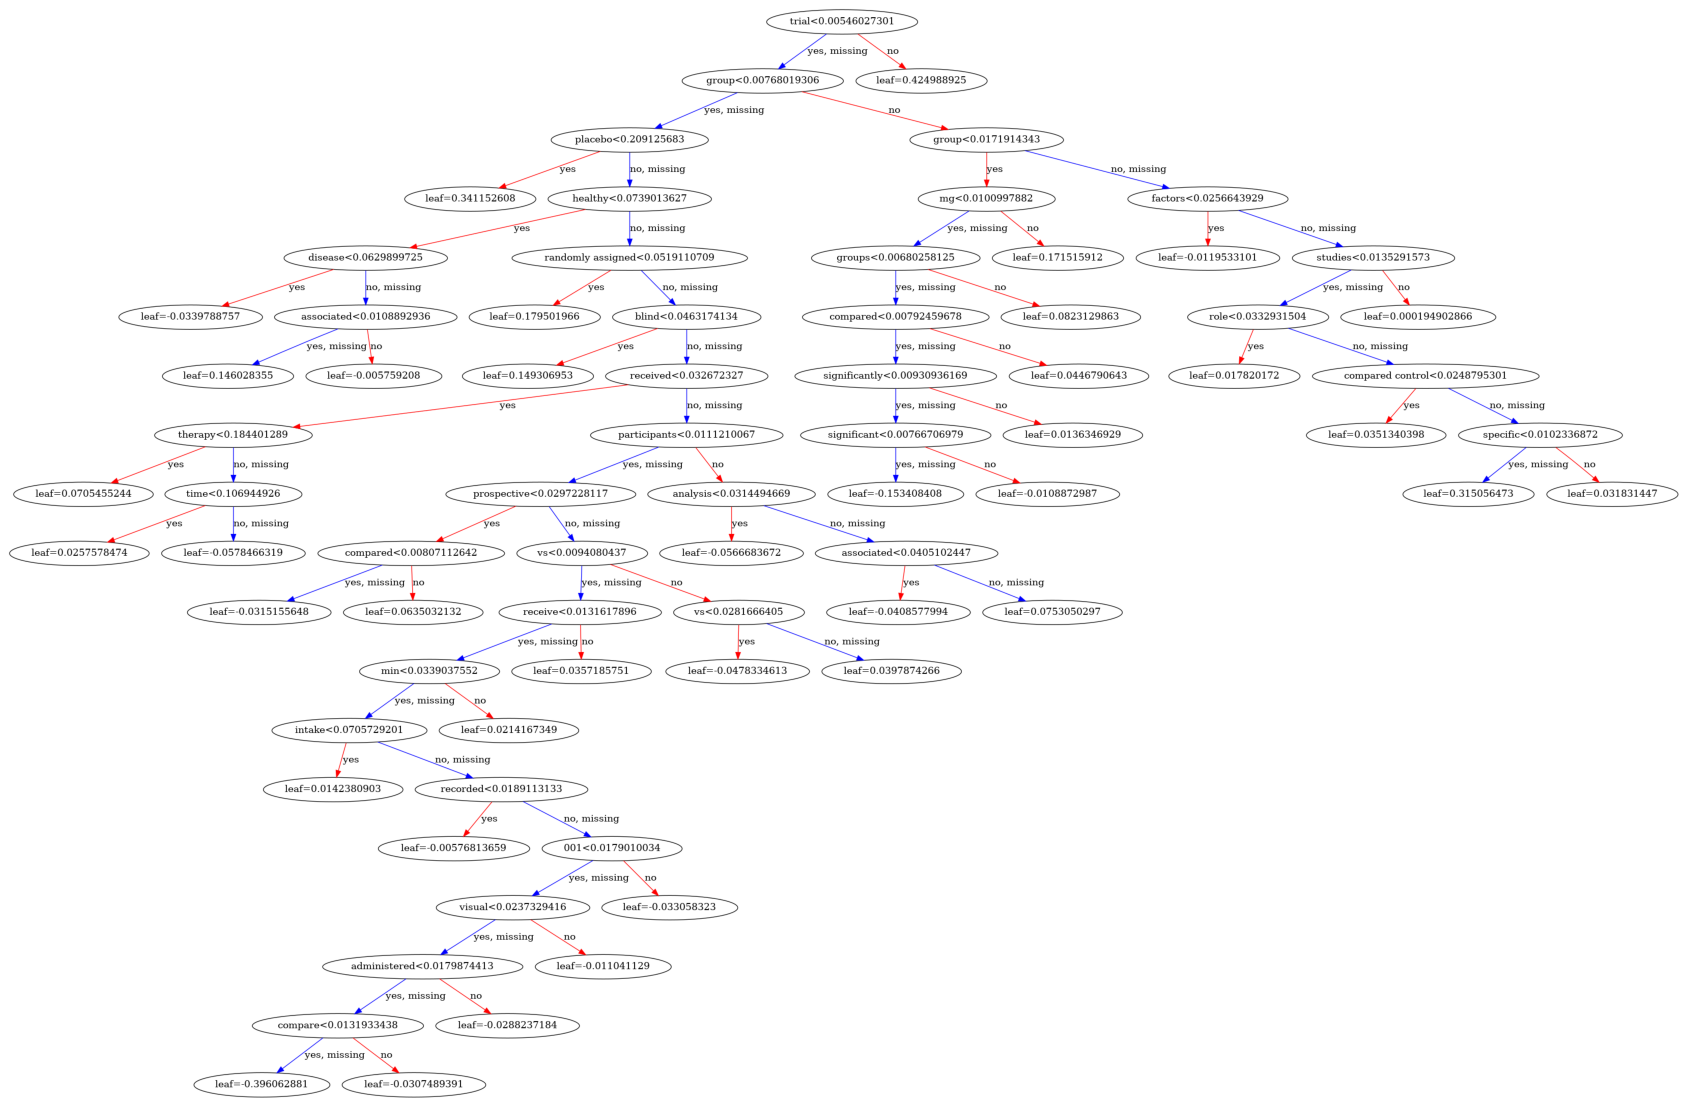

In [84]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(30, 30))
plot_tree(xgbclass, num_trees=1, ax=ax, feature_names=names)
plt.show()